In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

Dataset: Bike Traffic Counts https://data.seattle.gov/<br>
Time Period: 2014 - 2022<br>
Location: Seattle, WA<br>
Description: This dataset contains bike traffic counts recorded at various locations in Seattle, Washington, from 2014 to 2022.

#### Fremont Bridge Bicycle Counter

The Fremont Bridge Bicycle Counter began operation in October 2012 and records the number of bikes that cross the bridge using the pedestrian/bicycle pathways. Inductive loops on the east and west pathways count the passing of bicycles regardless of travel direction. The data consists of a date/time field: Date, east pathway count field: Fremont Bridge NB, and west pathway count field: Fremont Bridge SB. The count fields represent the total bicycles detected during the specified one hour period. Direction of travel is not specified, but in general most traffic in the Fremont Bridge NB field is travelling northbound and most traffic in the Fremont Bridge SB field is travelling southbound.

#### Broadway Cycle Track North Of E Union St Bicycle Counter (Out of Service) Last updated December 2023.

Due to hardware issues, this counter is no longer in service. Counts are conducted using tubes on a quarterly basis.
The counters consist of two small tube sensors stretching across the street, which are attached to a small metal counting box made by Eco-Counter. The tubes only count people riding bikes. They are very accurate and designed to be used on greenways and cycle tracks.

#### Burke Gilman Trail north of NE 70th St Bicycle and Pedestrian Counter

These sensors counts both people riding bikes and pedestrians. Separate volumes are tallied for each travel mode. Wires in a diamond formation in the concrete detect bikes and an infrared sensor mounted on a wooden post detects pedestrians. The counters also capture the direction of travel for both bikes and pedestrians.

### Broadway Cycle Track North Of E Union St Bicycle Counter

In [2]:
df_broadway = pd.read_csv('./back_end/Broadway_Cycle_Track_North_Of_E_Union_St_Bicycle_Counter.csv')

In [3]:
df_broadway.head()

,Date,Broadway Cycle Track North Of E Union St Total,NB,SB
0,01/01/2019 12:00:00 AM,5.0,2.0,3.0
1,01/01/2019 01:00:00 AM,15.0,4.0,11.0
2,01/01/2019 02:00:00 AM,3.0,1.0,2.0
3,01/01/2019 03:00:00 AM,0.0,0.0,0.0
4,01/01/2019 04:00:00 AM,1.0,0.0,1.0


In [4]:
df_broadway.shape

(63552, 4)

In [5]:
df_broadway.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63552 entries, 0 to 63551
Data columns (total 4 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Date                                            63552 non-null  object 
 1   Broadway Cycle Track North Of E Union St Total  63548 non-null  float64
 2   NB                                              63548 non-null  float64
 3   SB                                              63548 non-null  float64
dtypes: float64(3), object(1)
memory usage: 1.9+ MB


In [6]:
df_broadway.isna().sum()

Date                                              0
Broadway Cycle Track North Of E Union St Total    4
NB                                                4
SB                                                4
dtype: int64

In [7]:
df_broadway.describe()

,Broadway Cycle Track North Of E Union St Total,NB,SB
count,63548.000000,63548.000000,63548.000000
mean,11.915576,5.601026,6.314550
std,12.188538,6.602593,6.716115
min,0.000000,0.000000,0.000000
25%,2.000000,1.000000,1.000000
50%,9.000000,4.000000,4.000000
75%,18.000000,8.000000,9.000000
max,140.000000,99.000000,132.000000


In [8]:
df_broadway['Date'] = pd.to_datetime(df_broadway['Date'])

In [9]:
#df_broadway['Date'] = df_broadway['Date'].dt.strftime("%d/%m/%Y %H:%M")


In [10]:
df_broadway.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63552 entries, 0 to 63551
Data columns (total 4 columns):
 #   Column                                          Non-Null Count  Dtype         
---  ------                                          --------------  -----         
 0   Date                                            63552 non-null  datetime64[ns]
 1   Broadway Cycle Track North Of E Union St Total  63548 non-null  float64       
 2   NB                                              63548 non-null  float64       
 3   SB                                              63548 non-null  float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 1.9 MB


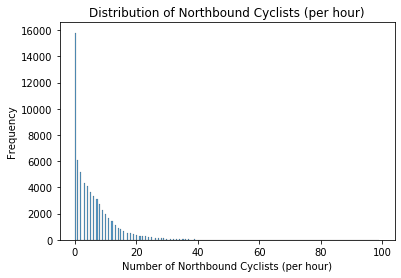

In [11]:
# Histogram for northbound cyclists
sns.histplot(df_broadway["NB"])
plt.xlabel("Number of Northbound Cyclists (per hour)")
plt.ylabel("Frequency")
plt.title("Distribution of Northbound Cyclists (per hour)")
plt.show()

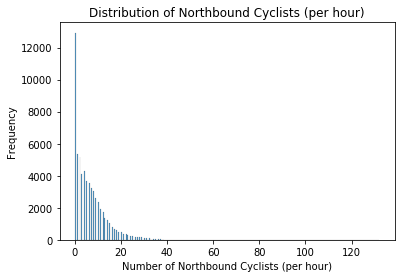

In [12]:
# Histogram for northbound cyclists
sns.histplot(df_broadway["SB"])
plt.xlabel("Number of Northbound Cyclists (per hour)")
plt.ylabel("Frequency")
plt.title("Distribution of Northbound Cyclists (per hour)")
plt.show()

In [13]:
###Impute missing values with Median

# Calculate median values for each column
median_NB = df_broadway['NB'].median()
median_SB = df_broadway['SB'].median()

# Impute missing values with the calculated medians
df_broadway['NB'].fillna(median_NB, inplace=True)
df_broadway['SB'].fillna(median_SB, inplace=True)


In [14]:
df_broadway['Broadway Cycle Track North Of E Union St Total'] = df_broadway['NB']+ df_broadway['SB']

### Burke Gilman Trail north of NE 70th St Bicycle and Pedestrian Counter

In [15]:
df_burke_gilman = pd.read_csv('./back_end/Burke_Gilman_Trail_north_of_NE_70th_St_Bicycle_and_Pedestrian_Counter.csv')

In [16]:
df_burke_gilman.head()

,Date,BGT North of NE 70th Total,Ped South,Ped North,Bike North,Bike South
0,01/01/2019 12:00:00 AM,0.0,0.0,0.0,0.0,0.0
1,01/01/2019 01:00:00 AM,2.0,1.0,0.0,1.0,0.0
2,01/01/2019 02:00:00 AM,1.0,0.0,0.0,0.0,1.0
3,01/01/2019 03:00:00 AM,0.0,0.0,0.0,0.0,0.0
4,01/01/2019 04:00:00 AM,1.0,0.0,0.0,1.0,0.0


In [17]:
df_burke_gilman.shape

(68328, 6)

In [18]:
df_burke_gilman.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68328 entries, 0 to 68327
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        68328 non-null  object 
 1   BGT North of NE 70th Total  65957 non-null  float64
 2   Ped South                   57977 non-null  float64
 3   Ped North                   57977 non-null  float64
 4   Bike North                  65956 non-null  float64
 5   Bike South                  65956 non-null  float64
dtypes: float64(5), object(1)
memory usage: 3.1+ MB


In [19]:
df_burke_gilman['Date'] = pd.to_datetime(df_burke_gilman['Date'])

In [20]:
df_burke_gilman.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68328 entries, 0 to 68327
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Date                        68328 non-null  datetime64[ns]
 1   BGT North of NE 70th Total  65957 non-null  float64       
 2   Ped South                   57977 non-null  float64       
 3   Ped North                   57977 non-null  float64       
 4   Bike North                  65956 non-null  float64       
 5   Bike South                  65956 non-null  float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 3.1 MB


In [21]:
df_burke_gilman.isna().sum()

Date                              0
BGT North of NE 70th Total     2371
Ped South                     10351
Ped North                     10351
Bike North                     2372
Bike South                     2372
dtype: int64

In [22]:
df_burke_gilman.describe()

,BGT North of NE 70th Total,Ped South,Ped North,Bike North,Bike South
count,65957.000000,57977.000000,57977.000000,65956.000000,65956.000000
mean,69.785481,19.513014,9.424582,20.569289,23.237962
std,171.624247,126.707760,38.957099,31.884526,58.670659
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,1.000000
50%,30.000000,5.000000,4.000000,7.000000,9.000000
75%,92.000000,14.000000,13.000000,28.000000,33.000000
max,10493.000000,4054.000000,4095.000000,794.000000,8191.000000


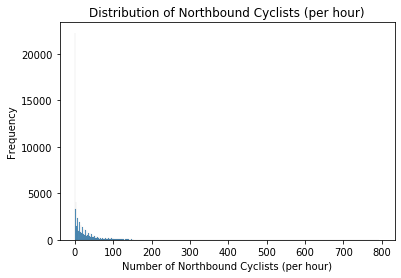

In [23]:
# Histogram for northbound cyclists
sns.histplot(df_burke_gilman["Bike North"])
plt.xlabel("Number of Northbound Cyclists (per hour)")
plt.ylabel("Frequency")
plt.title("Distribution of Northbound Cyclists (per hour)")
plt.show()

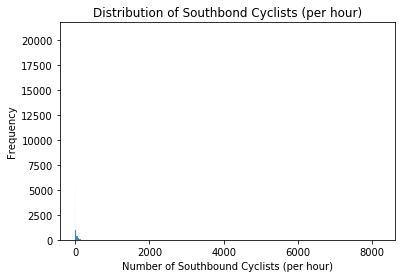

In [24]:
# Histogram for northbound cyclists
sns.histplot(df_burke_gilman["Bike South"])
plt.xlabel("Number of Southbound Cyclists (per hour)")
plt.ylabel("Frequency")
plt.title("Distribution of Southbond Cyclists (per hour)")
plt.show()

In [25]:
df_burke_gilman.isna().sum()

Date                              0
BGT North of NE 70th Total     2371
Ped South                     10351
Ped North                     10351
Bike North                     2372
Bike South                     2372
dtype: int64

In [26]:
### Impute missing values with Median, because there are outliers. 


# Calculate median values for each column
median_ped_south = df_burke_gilman['Ped South'].median()
median_ped_north = df_burke_gilman['Ped North'].median()
median_bike_north = df_burke_gilman['Bike North'].median()
median_bike_south = df_burke_gilman['Bike South'].median()

# Impute missing values with the calculated medians
df_burke_gilman['Ped South'].fillna(median_ped_south, inplace=True)
df_burke_gilman['Ped North'].fillna(median_ped_north, inplace=True)
df_burke_gilman['Bike North'].fillna(median_bike_north, inplace=True)
df_burke_gilman['Bike South'].fillna(median_bike_south, inplace=True)



In [27]:
# Calculate the 'Total' column
df_burke_gilman['BGT North of NE 70th Total'] = df_burke_gilman['Ped South'] + df_burke_gilman['Ped North'] + df_burke_gilman['Bike North'] + df_burke_gilman['Bike South']


In [28]:
df_burke_gilman.describe()

,BGT North of NE 70th Total,Ped South,Ped North,Bike North,Bike South
count,68328.000000,68328.000000,68328.000000,68328.000000,68328.000000
mean,68.759176,17.314439,8.602813,20.098232,22.743692
std,168.538021,116.832133,35.937797,31.424523,57.702170
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,0.000000,0.000000,1.000000,1.000000
50%,28.000000,5.000000,4.000000,7.000000,9.000000
75%,89.000000,13.000000,11.000000,27.000000,32.000000
max,10493.000000,4054.000000,4095.000000,794.000000,8191.000000


### Fremont Bridge Bicycle Counter

In [29]:
df_freemont = pd.read_csv('./back_end/Fremont_Bike.csv')

In [30]:
df_freemont.head()

,Date,"Fremont Bridge Sidewalks, south of N 34th St","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk"
0,02/28/2023 11:00:00 PM,6.0,3.0,3.0
1,02/28/2023 10:00:00 PM,14.0,5.0,9.0
2,02/28/2023 09:00:00 PM,30.0,13.0,17.0
3,02/28/2023 08:00:00 PM,37.0,22.0,15.0
4,02/28/2023 07:00:00 PM,59.0,19.0,40.0


In [31]:
df_freemont.shape

(91224, 4)

In [32]:
df_freemont.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91224 entries, 0 to 91223
Data columns (total 4 columns):
 #   Column                                                              Non-Null Count  Dtype  
---  ------                                                              --------------  -----  
 0   Date                                                                91224 non-null  object 
 1   Fremont Bridge Sidewalks, south of N 34th St                        91210 non-null  float64
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  91210 non-null  float64
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  91210 non-null  float64
dtypes: float64(3), object(1)
memory usage: 2.8+ MB


In [33]:
df_freemont.isna().sum()

Date                                                                   0
Fremont Bridge Sidewalks, south of N 34th St                          14
Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk    14
Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk    14
dtype: int64

In [34]:
df_freemont.describe()

,"Fremont Bridge Sidewalks, south of N 34th St","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk"
count,91210.000000,91210.000000,91210.000000
mean,105.603859,47.193882,58.409977
std,133.270779,60.779588,82.619206
min,0.000000,0.000000,0.000000
25%,13.000000,6.000000,7.000000
50%,58.000000,26.000000,30.000000
75%,142.000000,65.000000,75.000000
max,1097.000000,698.000000,850.000000


In [35]:
df_freemont.columns

Index(['Date', 'Fremont Bridge Sidewalks, south of N 34th St',
       'Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk',
       'Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'],
      dtype='object')

In [36]:
df_freemont['Date'] = pd.to_datetime(df_freemont['Date'])

In [37]:
# Filter data for the years 2014 to 2022
df_freemont = df_freemont[(df_freemont['Date'].dt.year >= 2014) & (df_freemont['Date'].dt.year <= 2022)]

In [38]:
df_freemont.shape

(78888, 4)

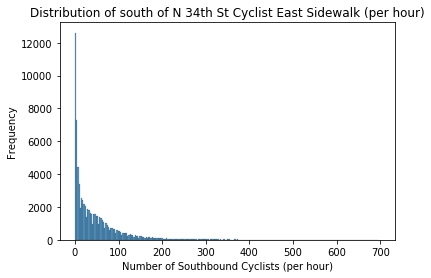

In [39]:
# Histogram for northbound cyclists
sns.histplot(df_freemont['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'])
plt.xlabel("Number of Southbound Cyclists (per hour)")
plt.ylabel("Frequency")
plt.title("Distribution of south of N 34th St Cyclist East Sidewalk (per hour)")
plt.show()

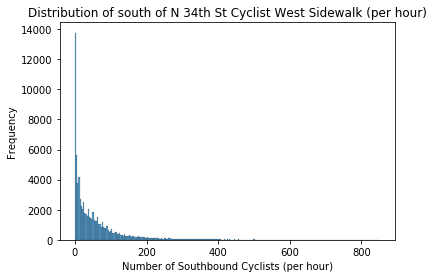

In [40]:
# Histogram for northbound cyclists
sns.histplot(df_freemont["Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk"])
plt.xlabel("Number of Southbound Cyclists (per hour)")
plt.ylabel("Frequency")
plt.title("Distribution of south of N 34th St Cyclist West Sidewalk (per hour)")
plt.show()

In [41]:
### Impute missing values with Median 


# Calculate median values for each column
median_bike_east = df_freemont['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].median()
median_bike_west = df_freemont['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].median()

# Impute missing values with the calculated medians
df_freemont['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].fillna(median_bike_east, inplace=True)
df_freemont['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].fillna(median_bike_west, inplace=True)




In [42]:
# Calculate the 'Total' column
df_freemont['Fremont Bridge Sidewalks, south of N 34th St'] = df_freemont['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'] + df_freemont['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk']

### Extraction on the timestamps (months, years, days, weekday/weekend, day, night, hours)

In [43]:
#df_broadway.head()
#df_broadway.info()
#df_burke_gilman.head()
df_freemont.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 78888 entries, 1416 to 80303
Data columns (total 4 columns):
 #   Column                                                              Non-Null Count  Dtype         
---  ------                                                              --------------  -----         
 0   Date                                                                78888 non-null  datetime64[ns]
 1   Fremont Bridge Sidewalks, south of N 34th St                        78888 non-null  float64       
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  78888 non-null  float64       
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  78888 non-null  float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 3.0 MB


In [44]:
df_broadway['Year'] = df_broadway['Date'].dt.year
df_broadway['Month'] = df_broadway['Date'].dt.month
df_broadway['Day'] = df_broadway['Date'].dt.day
df_broadway['Hour'] = df_broadway['Date'].dt.hour
df_broadway['Weekday'] = df_broadway['Date'].dt.weekday

In [45]:
df_burke_gilman['Year'] = df_burke_gilman['Date'].dt.year
df_burke_gilman['Month'] = df_burke_gilman['Date'].dt.month
df_burke_gilman['Day'] = df_burke_gilman['Date'].dt.day
df_burke_gilman['Hour'] = df_burke_gilman['Date'].dt.hour
df_burke_gilman['Weekday'] = df_burke_gilman['Date'].dt.weekday

In [46]:
df_freemont['Year'] = df_freemont['Date'].dt.year
df_freemont['Month'] = df_freemont['Date'].dt.month
df_freemont['Day'] = df_freemont['Date'].dt.day
df_freemont['Hour'] = df_freemont['Date'].dt.hour
df_freemont['Weekday'] = df_freemont['Date'].dt.weekday

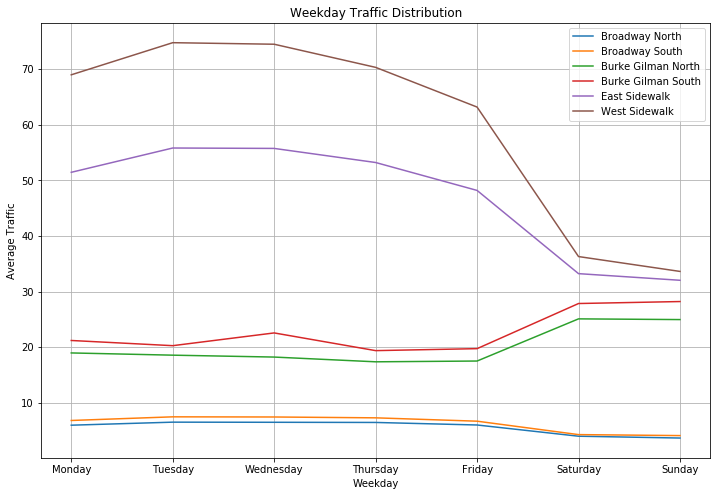

In [59]:
weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

# Map weekday numbers to weekday names and assign to a new column
df_broadway['Weekday_Name'] = df_broadway['Date'].dt.weekday.map(weekday_names)


# Group data by hour and calculate average traffic for northbound and southbound separately
weekday_traffic_df_broadway_NB = df_broadway.groupby('Weekday_Name')['NB'].mean()
weekday_traffic_df_broadway_SB = df_broadway.groupby('Weekday_Name')['SB'].mean()
weekday_traffic_df_burke_gilman_NB = df_burke_gilman.groupby('Weekday_Name')['Bike North'].mean()
weekday_traffic_df_burke_gilman_SB = df_burke_gilman.groupby('Weekday_Name')['Bike South'].mean()
weekday_traffic_df_freemont_ES = df_freemont.groupby('Weekday_Name')['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].mean()
weekday_traffic_df_freemont_WS = df_freemont.groupby('Weekday_Name')['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].mean()




# Define the order of weekdays
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']





plt.figure(figsize=(12, 8))

# Plot northbound traffic
plt.plot(weekday_traffic_df_broadway_NB.reindex(weekday_order).index, 
         weekday_traffic_df_broadway_NB.reindex(weekday_order).values, label='Broadway North')

# Plot southbound traffic
plt.plot(weekday_traffic_df_broadway_SB.reindex(weekday_order).index, 
         weekday_traffic_df_broadway_SB.reindex(weekday_order).values, label='Broadway South')


plt.plot(weekday_traffic_df_burke_gilman_NB.reindex(weekday_order).index, 
         weekday_traffic_df_burke_gilman_NB.reindex(weekday_order).values, label='Burke Gilman North')

# Plot southbound traffic
plt.plot(weekday_traffic_df_burke_gilman_SB.reindex(weekday_order).index, 
         weekday_traffic_df_burke_gilman_SB.reindex(weekday_order).values, label='Burke Gilman South')


# Plot northbound traffic
plt.plot(weekday_traffic_df_freemont_ES.reindex(weekday_order).index, 
         weekday_traffic_df_freemont_ES.reindex(weekday_order).values, label='East Sidewalk')

# Plot southbound traffic
plt.plot(weekday_traffic_df_freemont_WS.reindex(weekday_order).index, 
        weekday_traffic_df_freemont_WS.reindex(weekday_order).values, label='West Sidewalk')




# Set x-axis tick labels to weekday names
plt.xticks(range(7), weekday_order)

plt.xlabel('Weekday')
plt.ylabel('Average Traffic')
plt.title('Weekday Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()




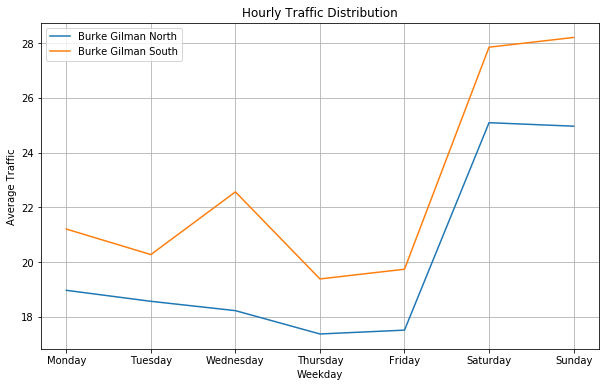

In [48]:
# Group data by hour and calculate average traffic for northbound and southbound separately

weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

# Map weekday numbers to weekday names and assign to a new column
df_burke_gilman['Weekday_Name'] = df_burke_gilman['Date'].dt.weekday.map(weekday_names)


weekday_traffic_df_burke_gilman_NB = df_burke_gilman.groupby('Weekday_Name')['Bike North'].mean()
weekday_traffic_df_burke_gilman_SB = df_burke_gilman.groupby('Weekday_Name')['Bike South'].mean()

# Define the order of weekdays
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 
plt.figure(figsize=(10, 6))

# Plot northbound traffic
plt.plot(weekday_traffic_df_burke_gilman_NB.reindex(weekday_order).index, 
         weekday_traffic_df_burke_gilman_NB.reindex(weekday_order).values, label='Burke Gilman North')

# Plot southbound traffic
plt.plot(weekday_traffic_df_burke_gilman_SB.reindex(weekday_order).index, 
         weekday_traffic_df_burke_gilman_SB.reindex(weekday_order).values, label='Burke Gilman South')

# Set x-axis tick labels to weekday names
plt.xticks(range(7), weekday_order)

plt.xlabel('Weekday')
plt.ylabel('Average Traffic')
plt.title('Hourly Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()



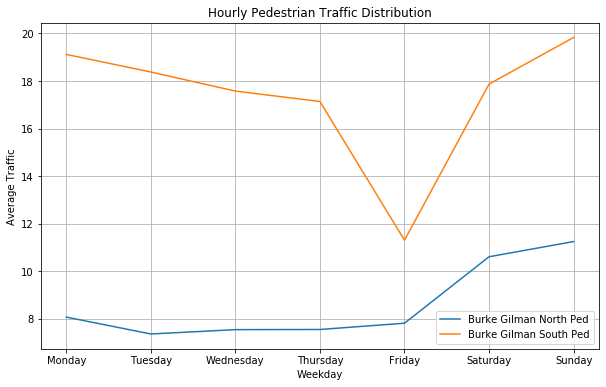

In [49]:
# Group data by hour and calculate average traffic for northbound and southbound separately

weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

# Map weekday numbers to weekday names and assign to a new column
df_burke_gilman['Weekday_Name'] = df_burke_gilman['Date'].dt.weekday.map(weekday_names)


weekday_traffic_df_burke_gilman_NB = df_burke_gilman.groupby('Weekday_Name')['Ped North'].mean()
weekday_traffic_df_burke_gilman_SB = df_burke_gilman.groupby('Weekday_Name')['Ped South'].mean()

# Define the order of weekdays
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 
plt.figure(figsize=(10, 6))

# Plot northbound traffic
plt.plot(weekday_traffic_df_burke_gilman_NB.reindex(weekday_order).index, 
         weekday_traffic_df_burke_gilman_NB.reindex(weekday_order).values, label='Burke Gilman North Ped')

# Plot southbound traffic
plt.plot(weekday_traffic_df_burke_gilman_SB.reindex(weekday_order).index, 
         weekday_traffic_df_burke_gilman_SB.reindex(weekday_order).values, label='Burke Gilman South Ped')

# Set x-axis tick labels to weekday names
plt.xticks(range(7), weekday_order)

plt.xlabel('Weekday')
plt.ylabel('Average Traffic')
plt.title('Hourly Pedestrian Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()


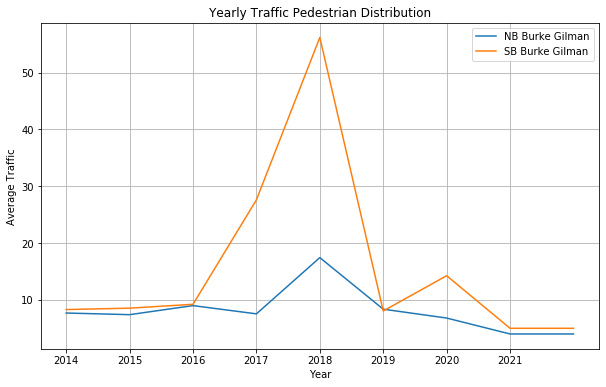

In [63]:
#Group data by hour and calculate average traffic 


year_traffic_df_burke_gilman_BN = df_burke_gilman.groupby('Year')['Ped North'].mean()
year_traffic_df_burke_gilman_BS = df_burke_gilman.groupby('Year')['Ped South'].mean()


# the yearly traffic for each location 

plt.figure(figsize=(10, 6))


plt.plot(year_traffic_df_burke_gilman_BN .index, year_traffic_df_burke_gilman_BN.values, label='NB Burke Gilman')
plt.plot(year_traffic_df_burke_gilman_BS.index, year_traffic_df_burke_gilman_BS.values, label='SB Burke Gilman')





# Combine all years from the indices of the DataFrames
all_years = []

all_years.extend(year_traffic_df_burke_gilman_BN.index)
all_years.extend(year_traffic_df_burke_gilman_BS.index)


# Set x-axis ticks to cover all years present in the data
plt.xticks(range(min(all_years), max(all_years)))

plt.xlabel('Year')
plt.ylabel('Average Traffic')
plt.title('Yearly Traffic Pedestrian Distribution')
plt.legend()
plt.grid(True)
plt.show()



In [50]:
df_freemont.head()

,Date,"Fremont Bridge Sidewalks, south of N 34th St","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk",Year,Month,Day,Hour,Weekday
1416,2022-12-31 23:00:00,25.0,15.0,10.0,2022,12,31,23,5
1417,2022-12-31 22:00:00,23.0,15.0,8.0,2022,12,31,22,5
1418,2022-12-31 21:00:00,16.0,6.0,10.0,2022,12,31,21,5
1419,2022-12-31 20:00:00,20.0,13.0,7.0,2022,12,31,20,5
1420,2022-12-31 19:00:00,14.0,6.0,8.0,2022,12,31,19,5


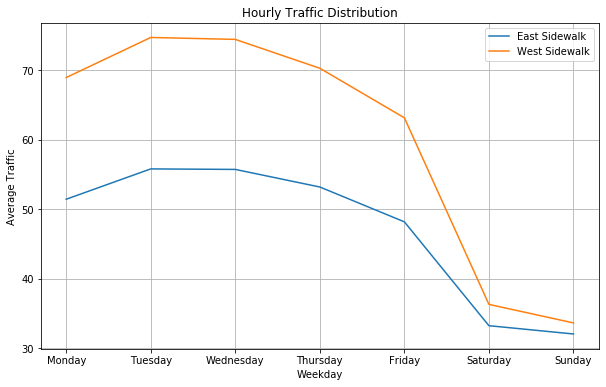

In [51]:
weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

# Map weekday numbers to weekday names and assign to a new column
df_freemont['Weekday_Name'] = df_freemont['Date'].dt.weekday.map(weekday_names)


# Group data by hour and calculate average traffic for northbound and southbound separately
weekday_traffic_df_freemont_ES = df_freemont.groupby('Weekday_Name')['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].mean()
weekday_traffic_df_freemont_WS = df_freemont.groupby('Weekday_Name')['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].mean()

# Define the order of weekdays
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']


plt.figure(figsize=(10, 6))

# Plot northbound traffic
plt.plot(weekday_traffic_df_freemont_ES.reindex(weekday_order).index, 
         weekday_traffic_df_freemont_ES.reindex(weekday_order).values, label='East Sidewalk')

# Plot southbound traffic
plt.plot(weekday_traffic_df_freemont_WS.reindex(weekday_order).index, 
        weekday_traffic_df_freemont_WS.reindex(weekday_order).values, label='West Sidewalk')

# Set x-axis tick labels to weekday names
plt.xticks(range(7), weekday_order)

plt.xlabel('Weekday')
plt.ylabel('Average Traffic')
plt.title('Hourly Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()


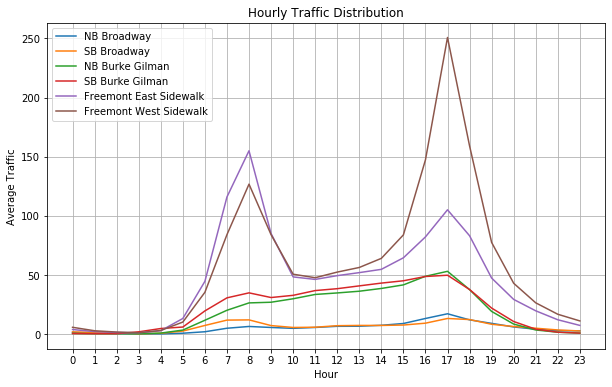

In [52]:
 #Group data by hour and calculate average traffic 
hourly_traffic_df_broadway_NB = df_broadway.groupby('Hour')['NB'].mean()
hourly_traffic_df_broadway_SB = df_broadway.groupby('Hour')['SB'].mean()


hourly_traffic_df_burke_gilman_BN = df_burke_gilman.groupby('Hour')['Bike North'].mean()
hourly_traffic_df_burke_gilman_BS = df_burke_gilman.groupby('Hour')['Bike South'].mean()


hourly_traffic_df_freemont_ES = df_freemont.groupby('Hour')['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].mean()
hourly_traffic_df_freemont_WS = df_freemont.groupby('Hour')['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].mean()

#df_broadway.info()
#df_burke_gilman.head()
#df_freemont.info()


# the hourly traffic for each location 

plt.figure(figsize=(10, 6))
plt.plot(hourly_traffic_df_broadway_NB.index, hourly_traffic_df_broadway_NB.values, label='NB Broadway')
plt.plot(hourly_traffic_df_broadway_SB.index, hourly_traffic_df_broadway_SB.values, label='SB Broadway')

plt.plot(hourly_traffic_df_burke_gilman_BN .index, hourly_traffic_df_burke_gilman_BN.values, label='NB Burke Gilman')
plt.plot(hourly_traffic_df_burke_gilman_BS.index, hourly_traffic_df_burke_gilman_BS.values, label='SB Burke Gilman')

plt.plot(hourly_traffic_df_freemont_ES.index, hourly_traffic_df_freemont_ES.values, label='Freemont East Sidewalk')
plt.plot(hourly_traffic_df_freemont_WS.index, hourly_traffic_df_freemont_WS.values, label='Freemont West Sidewalk')








plt.xticks(range(0, 24))
plt.xlabel('Hour')
plt.ylabel('Average Traffic')
plt.title('Hourly Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()




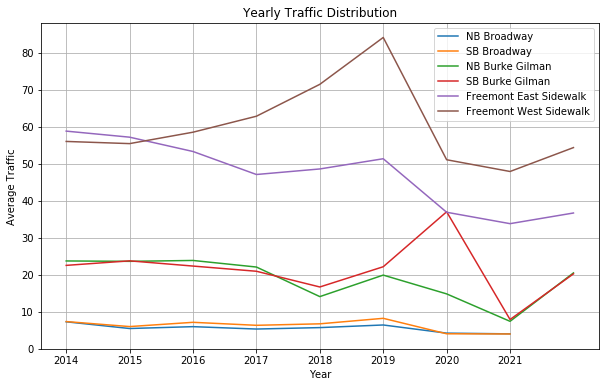

In [53]:
#Group data by hour and calculate average traffic 
year_traffic_df_broadway_NB = df_broadway.groupby('Year')['NB'].mean()
year_traffic_df_broadway_SB = df_broadway.groupby('Year')['SB'].mean()


year_traffic_df_burke_gilman_BN = df_burke_gilman.groupby('Year')['Bike North'].mean()
year_traffic_df_burke_gilman_BS = df_burke_gilman.groupby('Year')['Bike South'].mean()


year_traffic_df_freemont_ES = df_freemont.groupby('Year')['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].mean()
year_traffic_df_freemont_WS = df_freemont.groupby('Year')['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].mean()

#df_broadway.info()
#df_burke_gilman.head()
#df_freemont.info()


# the yearly traffic for each location 

plt.figure(figsize=(10, 6))
plt.plot(year_traffic_df_broadway_NB.index, year_traffic_df_broadway_NB.values, label='NB Broadway')
plt.plot(year_traffic_df_broadway_SB.index, year_traffic_df_broadway_SB.values, label='SB Broadway')

plt.plot(year_traffic_df_burke_gilman_BN .index, year_traffic_df_burke_gilman_BN.values, label='NB Burke Gilman')
plt.plot(year_traffic_df_burke_gilman_BS.index, year_traffic_df_burke_gilman_BS.values, label='SB Burke Gilman')

plt.plot(year_traffic_df_freemont_ES.index, year_traffic_df_freemont_ES.values, label='Freemont East Sidewalk')
plt.plot(year_traffic_df_freemont_WS.index, year_traffic_df_freemont_WS.values, label='Freemont West Sidewalk')



# Combine all years from the indices of the DataFrames
all_years = []
all_years.extend(year_traffic_df_broadway_NB.index)
all_years.extend(year_traffic_df_broadway_SB.index)
all_years.extend(year_traffic_df_burke_gilman_BN.index)
all_years.extend(year_traffic_df_burke_gilman_BS.index)
all_years.extend(year_traffic_df_freemont_ES.index)
all_years.extend(year_traffic_df_freemont_WS.index)

# Set x-axis ticks to cover all years present in the data
plt.xticks(range(min(all_years), max(all_years)))

plt.xlabel('Year')
plt.ylabel('Average Traffic')
plt.title('Yearly Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()



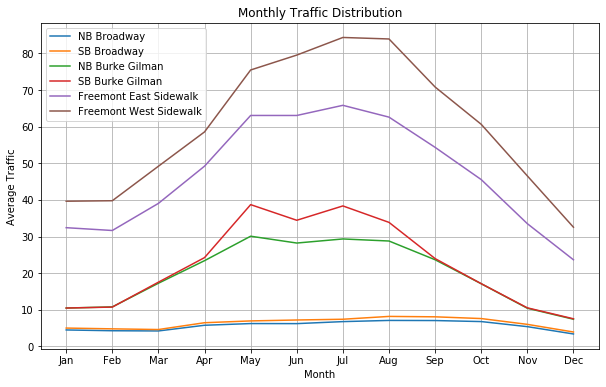

In [54]:
#Group data by hour and calculate average traffic 
month_traffic_df_broadway_NB = df_broadway.groupby('Month')['NB'].mean()
month_traffic_df_broadway_SB = df_broadway.groupby('Month')['SB'].mean()


month_traffic_df_burke_gilman_BN = df_burke_gilman.groupby('Month')['Bike North'].mean()
month_traffic_df_burke_gilman_BS = df_burke_gilman.groupby('Month')['Bike South'].mean()


month_traffic_df_freemont_ES = df_freemont.groupby('Month')['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].mean()
month_traffic_df_freemont_WS = df_freemont.groupby('Month')['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].mean()

#df_broadway.info()
#df_burke_gilman.head()
#df_freemont.info()


# the yearly traffic for each location 

plt.figure(figsize=(10, 6))
plt.plot(month_traffic_df_broadway_NB.index, month_traffic_df_broadway_NB.values, label='NB Broadway')
plt.plot(month_traffic_df_broadway_SB.index, month_traffic_df_broadway_SB.values, label='SB Broadway')

plt.plot(month_traffic_df_burke_gilman_BN .index, month_traffic_df_burke_gilman_BN.values, label='NB Burke Gilman')
plt.plot(month_traffic_df_burke_gilman_BS.index, month_traffic_df_burke_gilman_BS.values, label='SB Burke Gilman')

plt.plot(month_traffic_df_freemont_ES.index, month_traffic_df_freemont_ES.values, label='Freemont East Sidewalk')
plt.plot(month_traffic_df_freemont_WS.index, month_traffic_df_freemont_WS.values, label='Freemont West Sidewalk')

# Set x-axis ticks to display month names
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

plt.xlabel('Month')
plt.ylabel('Average Traffic')
plt.title('Monthly Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()



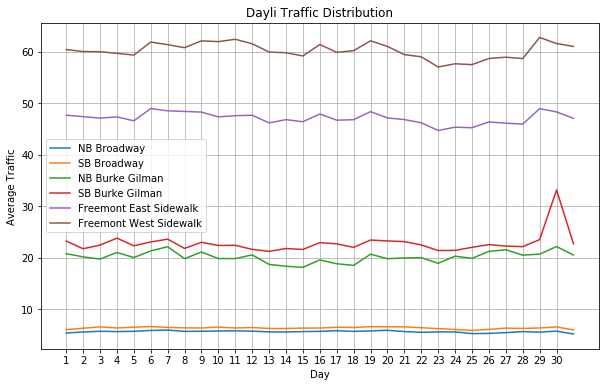

In [55]:
#Group data by hour and calculate average traffic 
year_traffic_df_broadway_NB = df_broadway.groupby('Day')['NB'].mean()
year_traffic_df_broadway_SB = df_broadway.groupby('Day')['SB'].mean()


year_traffic_df_burke_gilman_BN = df_burke_gilman.groupby('Day')['Bike North'].mean()
year_traffic_df_burke_gilman_BS = df_burke_gilman.groupby('Day')['Bike South'].mean()


year_traffic_df_freemont_ES = df_freemont.groupby('Day')['Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk'].mean()
year_traffic_df_freemont_WS = df_freemont.groupby('Day')['Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk'].mean()

#df_broadway.info()
#df_burke_gilman.head()
#df_freemont.info()


# the yearly traffic for each location 

plt.figure(figsize=(10, 6))
plt.plot(year_traffic_df_broadway_NB.index, year_traffic_df_broadway_NB.values, label='NB Broadway')
plt.plot(year_traffic_df_broadway_SB.index, year_traffic_df_broadway_SB.values, label='SB Broadway')

plt.plot(year_traffic_df_burke_gilman_BN .index, year_traffic_df_burke_gilman_BN.values, label='NB Burke Gilman')
plt.plot(year_traffic_df_burke_gilman_BS.index, year_traffic_df_burke_gilman_BS.values, label='SB Burke Gilman')

plt.plot(year_traffic_df_freemont_ES.index, year_traffic_df_freemont_ES.values, label='Freemont East Sidewalk')
plt.plot(year_traffic_df_freemont_WS.index, year_traffic_df_freemont_WS.values, label='Freemont West Sidewalk')



# Set x-axis ticks to cover all years present in the data
plt.xticks(range(1,31))

plt.xlabel('Day')
plt.ylabel('Average Traffic')
plt.title('Dayli Traffic Distribution')
plt.legend()
plt.grid(True)
plt.show()



### Statistical analysis

In [56]:
## Statistical tests (t-tests) to compare traffic patterns between different zones.

In [57]:
broadway_total = df_broadway['Broadway Cycle Track North Of E Union St Total']
burke_gilman_total = df_burke_gilman['BGT North of NE 70th Total']
freemont_total = df_freemont['Fremont Bridge Sidewalks, south of N 34th St']


In [58]:
# Perform pairwise t-tests
t_stat_BG, p_value_BG = ttest_ind(broadway_total, burke_gilman_total)
t_stat_BF, p_value_BF = ttest_ind(broadway_total, freemont_total)
t_stat_GF, p_value_GF = ttest_ind(burke_gilman_total, freemont_total)

# Print the results
print('Broadway vs. Burke Gilman:')
print('T-statistic:', t_stat_BG)
print('P-value:', p_value_BG)
print()

print('Broadway vs. Fremont:')
print('T-statistic:', t_stat_BF)
print('P-value:', p_value_BF)
print()

print('Burke Gilman vs. Fremont:')
print('T-statistic:', t_stat_GF)
print('P-value:', p_value_GF)

Broadway vs. Burke Gilman:
T-statistic: -84.81963105306866
P-value: 0.0

Broadway vs. Fremont:
T-statistic: -176.5907610674472
P-value: 0.0

Burke Gilman vs. Fremont:
T-statistic: -48.55717281816674
P-value: 0.0


#### Broadway vs. Burke Gilman:
T-Statistic: -84.82
P-Value: 0.0
The T-statistic of -84.82 indicates a significant difference in average heights between Broadway and Burke Gilman. The p-value of 0.0 suggests that this difference is statistically significant, leading to the rejection of the null hypothesis that there is no difference in average heights between the two locations.

#### Broadway vs. Fremont:
T-Statistic: -176.59
P-Value: 0.0
The T-statistic of -176.59 indicates a significant difference in average heights between Broadway and Fremont. The p-value of 0.0 suggests that this difference is statistically significant, leading to the rejection of the null hypothesis that there is no difference in average heights between the two locations.

#### Burke Gilman vs. Fremont:
T-Statistic: -48.56
P-Value: 0.0
The T-statistic of -48.56 indicates a significant difference in average heights between Burke Gilman and Fremont. The p-value of 0.0 suggests that this difference is statistically significant, leading to the rejection of the null hypothesis that there is no difference in average heights between the two locations.

In all three comparisons, the extremely low p-values indicate that the differences in average heights between the locations are statistically significant, and the null hypothesis can be rejected in favor of the alternative hypothesis that there are significant differences in heights between the groups.

The significant differences in average heights between locations (Broadway, Burke Gilman, and Fremont) may indicate varying demographics or user populations in those areas. This information can be used to understand the types of cyclists using each route.

****
#### Conclusion
Broadway has significantly fewer bike riders compared to Burke Gilman and Fremont. Similarly, Burke Gilman has fewer bike riders compared to Fremont.

Fremont appears to have the highest bike traffic volume among the three locations compared (Broadway, Burke Gilman, and Fremont). The statistical analysis suggests that Fremont has significantly higher mean total bike counts compared to both Broadway and Burke Gilman.